In [1]:
## What this code does ##
#1 Import packages
#2 Read in parameters
#3 Make circular pupil
#4 Make power spectrum distribution
#5 Generate phase screen (much bigger size than 'observe size')
#6 Make structure function
#7 Make orthonormalize zernike
#8 Generate 10,000 phase screens
#9 Fit zernike using orthonormalized method
#10 Make residual error plot

In [2]:
## 1 ## Import packages ##

from aotools import zernike
from aotools.turbulence import infinitephasescreen
from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import axes3d
from numpy import fft
import numpy as np
import pandas as pd
import random
import time

%matplotlib inline

In [3]:
## 2 ## Read in parameters ##

#n:   0 1 2 3  4  5  6   7   8   9   10   11   12   13    14    15    16
#2^n: 1 2 4 8 16 32 64 128 256 512 1024 2048 4096 8192 16384 32768 65536

#???suggested zernike<scrn_size*pixel_scale/2r0????
#radialDegree    1   2   3    4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19  20  21  22  23  24
#zernike(approx) 1   3   6   10  15  21  28  36  45  55  66  78  91 105 120 136 153 171 190 210 231 253 276 300

scrn_size=256 #pixel; int; for the whole phase screen; total pixel number = scrn_size*scrn_size pixel
sample_scrn_size=32 #pixel; int;  for the 'observation'
pixel_scale=0.1#m/pixel
r0=0.1 #m
L0=20. #m
l0=1e-10 #m
radialDegree=16 #int; piston = 1, tip/tilt=2, focus/defocus/astigmatism=3, 2trefoils/2comas=4, ...
Nrandomscreens=10000 #int; samplings
Nrandom=10000

Nzernike=int(radialDegree*(radialDegree+1)/2.0) #total number of zernike modes within given radial degree

color_map = plt.cm.get_cmap('Blues')
reversed_color_map = color_map.reversed()

##gram-schmidt cant solve - problem with phase screen at scrn_size=128,sample_scrn_size=128,pixel_scale=0.1,r0=0.1,L0=20.0,radialDegree=10,Nrandom=10000
##gram schmidt solve at scrn_size=512,sample_scrn_size=64,pixel_scale=0.08,r0=0.1,L0=20.0,radial_degree=11,Nrandom=10000
##not working scrn_size=256,sample_scrn_size=32,pixel_scale=0.8,r0=0.1,L0=20.0,radial_degree=8,Nrandom=10000

In [4]:
## 3 ## Make circular pupil ##
#inside pupil=1=true, outside=0=false
#pupil --> 2d array
#plat_pupil --> flatten 2d array

x=np.arange(sample_scrn_size)
x=x-(sample_scrn_size-1)/2.0
xx,yy=np.meshgrid(x,x)
r=np.sqrt(xx**2+yy**2)
pupil=np.zeros(r.shape) # inside circle=1=True
for i in range(r.shape[0]):
    for j in range(r.shape[1]):
        if r[i,j]<=sample_scrn_size/2.0:
            pupil[i,j]=1
        else:
            pupil[i,j]=0
            
flat_pupil=pupil.flatten()

C:\Users\gqmc62\Anaconda3\lib\site-packages\ipykernel_launcher.py:45: RuntimeWarning: divide by zero encountered in log


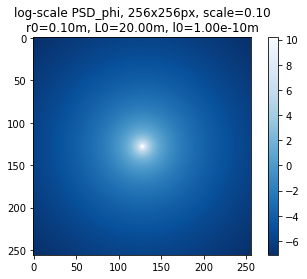

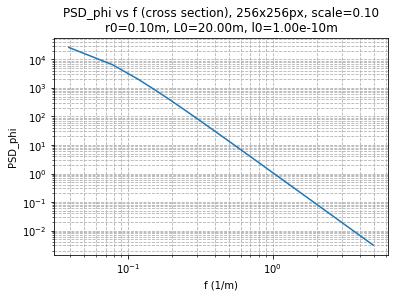

<Figure size 432x288 with 0 Axes>

In [5]:
## 4 ## Make power spectrum density ##
#got this section from ft_phase_screen in aotools/phasescreen.py

def ift2(G, delta_f, FFT=None):
    """
    Wrapper for inverse fourier transform

    Parameters:
        G: data to transform
        delta_f: pixel seperation
        FFT (FFT object, optional): An accelerated FFT object
    """

    N = G.shape[0]

    if FFT:
        g = numpy.fft.fftshift(FFT(numpy.fft.fftshift(G))) * (N * delta_f) ** 2
    else:
        g = fft.ifftshift(fft.ifft2(fft.fftshift(G))) * (N * delta_f) ** 2

    return g

phase_screen=infinitephasescreen.PhaseScreenVonKarman(scrn_size,pixel_scale,r0,L0)

FFT=None
N=phase_screen.stencil_length
delta = pixel_scale
l0 = l0
R = random.SystemRandom(time.time())
seed = int(R.random()*100000)
np.random.seed(seed)
del_f = 1./(N*delta)
fx = np.arange(-N/2, N/2) * del_f
(fx, fy) = np.meshgrid(fx,fx)
f = np.sqrt(fx**2. + fy**2.)
fm = 5.92/l0/(2*np.pi)
f0 = 1./L0
PSD_phi = (0.023*r0**(-5./3.) * np.exp(-1*((f/fm)**2)) / (((f**2) + (f0**2))**(11./6)))
PSD_phi[int(N/2), int(N/2)] = 0
cn = ((np.random.normal(size=(N, N))+1j * np.random.normal(size=(N, N))) * np.sqrt(PSD_phi)*del_f)
phs = ift2(cn, 1, FFT).real

#plots

plt.imshow(np.log(PSD_phi),cmap=reversed_color_map)
plt.colorbar()
plt.title('log-scale PSD_phi, {:d}x{:d}px, scale={:.2f}\n'.format(scrn_size,scrn_size,pixel_scale)
         +'r0={:.2f}m, L0={:.2f}m, l0={:.2e}m'.format(r0,L0,l0))
plt.savefig('PSD-logscale')
plt.show()
plt.clf()

#plt.loglog(fx[int(scrn_size/2),int(scrn_size/2)+1:-1],PSD_phi[int(scrn_size/2),int(scrn_size/2)+1:-1],ls='-')
plt.plot(fx[int(np.ceil(scrn_size/2.0)),int(np.ceil(scrn_size/2.0))+1:-1],PSD_phi[int(np.ceil(scrn_size/2.0)),int(np.ceil(scrn_size/2.0))+1:-1],ls='-')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('f (1/m)')
plt.ylabel('PSD_phi')
plt.grid(True,which="both", linestyle='--')
plt.title('PSD_phi vs f (cross section), {:d}x{:d}px, scale={:.2f}\n'.format(scrn_size,scrn_size,pixel_scale)
         +'r0={:.2f}m, L0={:.2f}m, l0={:.2e}m'.format(r0,L0,l0))
plt.savefig('PSD-cross-section')
plt.show()
plt.clf()

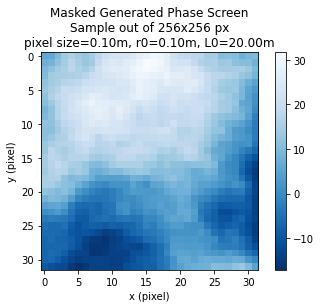

<Figure size 432x288 with 0 Axes>

In [6]:
## 5 ## Generate phase screen ##
#phase screen was actually generated in the last section
#phase_screen=infinitephasescreen.PhaseScreenVonKarman(scrn_size,pixel_scale,r0,L0)
phase=phase_screen.scrn

#plots

plt.imshow(phase[0:sample_scrn_size,0:sample_scrn_size],cmap=reversed_color_map)
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.title('Masked Generated Phase Screen\nSample out of {:d}x{:d} px\npixel size={:.2f}m, r0={:.2f}m, L0={:.2f}m'.format(scrn_size,scrn_size,pixel_scale,r0,L0))
plt.colorbar()
plt.savefig('sample-phase-screen')
plt.show()
plt.clf()

In [7]:
## 6 ## Make structure function ##
#choose point a to be 'center' within certain margin from edges
#choose point b to be 'displacement vector' within certain radius
phase=phase_screen.scrn
pointsa=np.zeros((Nrandom,2),dtype=int) # [,0]=x [,1]=y
pointsb=np.zeros((Nrandom,2),dtype=int) # be random shifted vectors limited to certain distance for easy cropping

for i in np.arange(Nrandom):
    pointsa[i,0]=random.randint(0,scrn_size-1)
    pointsa[i,1]=random.randint(0,scrn_size-1)
    pointsb[i,0]=random.randint(0,scrn_size-1)
    pointsb[i,1]=random.randint(0,scrn_size-1)

#calculate distance, phase, etc.

distance=np.zeros(Nrandom)
phase_difference=np.zeros(Nrandom)

for i in np.arange(Nrandom):
    phase_difference[i]=np.abs(phase[int(pointsa[i,0]),int(pointsa[i,1])]
                               -phase[int(pointsb[i,0]),int(pointsb[i,1])])
    distance[i]=np.sqrt((pointsa[i,0]-pointsb[i,0])**2+(pointsa[i,1]-pointsb[i,1])**2)*pixel_scale
    
#binning data ... not exactly binning but combining data with the same distance
    
x=set(distance)
x=list(x)
x=np.asarray(x)
x=np.sort(x)
ye=np.zeros(len(x))

y=[]

for i in x: # for coverd distance
    z=[]
    for j in np.arange(Nrandom):
        if distance[j]==i:
            z.append(phase_difference[j])
    y.append(z)

#calculate variance??? D_phi
    
var_phase=np.zeros(len(y))
for i in np.arange(len(y)):
    temp=0.
    if len(y[i])!=1:
        for j in np.arange(len(y[i])):
            temp=temp+(y[i][j]**2)
        temp=temp/len(y[i])
        var_phase[i]=temp
        ye[i]=temp/np.sqrt(2*len(y[i])-2)
    else:
        var_phase[i]=np.NaN
        ye[i]=np.NaN


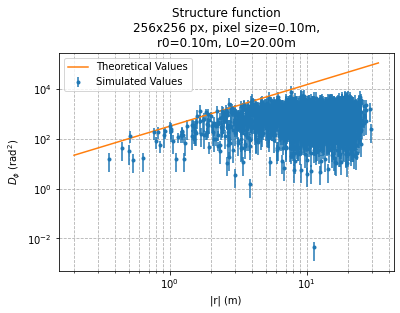

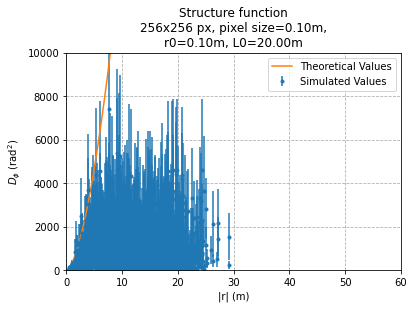

<Figure size 432x288 with 0 Axes>

In [8]:
#plots
    
plt.errorbar(x,var_phase,yerr=ye,ls='',marker='.',label='Simulated Values')
plt.plot(x,6.88*(x/r0)**(5./3.),ls='-',label='Theoretical Values')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('|r| (m)')
plt.ylabel('$D_\phi$ (rad$^2$)')
plt.grid(True,which="both", linestyle='--')
plt.legend()
plt.title('Structure function\n{:d}x{:d} px, pixel size={:.2f}m,\nr0={:.2f}m, L0={:.2f}m'.format(scrn_size,scrn_size,pixel_scale,r0,L0))
plt.savefig('structure-function-log-log')
plt.show()
plt.clf()

plt.errorbar(x,var_phase,yerr=ye,ls='',marker='.',label='Simulated Values')
plt.plot(x,6.88*(x/r0)**(5./3.),ls='-',label='Theoretical Values')
#plt.xscale('log')
#plt.yscale('log')
plt.xlim((0,60))
plt.ylim((0,10000))
plt.xlabel('|r| (m)')
plt.ylabel('$D_\phi$ (rad$^2$)')
plt.grid(True,which="both", linestyle='--')
plt.legend()
plt.title('Structure function\n{:d}x{:d} px, pixel size={:.2f}m,\nr0={:.2f}m, L0={:.2f}m'.format(scrn_size,scrn_size,pixel_scale,r0,L0))
plt.savefig('structure-function')
plt.show()
plt.clf()

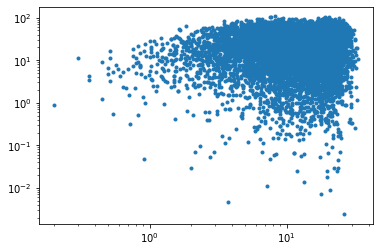

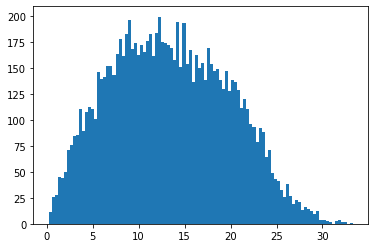

C:\Users\gqmc62\Anaconda3\lib\site-packages\ipykernel_launcher.py:41: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
C:\Users\gqmc62\Anaconda3\lib\site-packages\ipykernel_launcher.py:42: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.


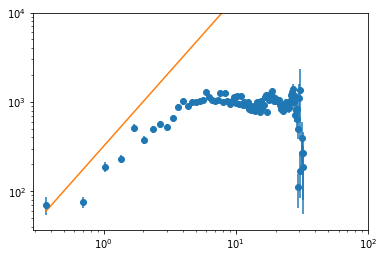

<Figure size 432x288 with 0 Axes>

In [9]:
plt.plot(distance,phase_difference,ls='',marker='.')
plt.xscale('log')
plt.yscale('log')
plt.show()
plt.clf()

plt.hist(distance,bins=100)
plt.show()
plt.clf()
mindis=min(distance)
maxdis=max(distance)
nbin=100
space=(maxdis-mindis)/nbin
distancegroup=space*np.arange(nbin+1)+mindis
phasegroup=[]
ye=np.zeros(nbin)
for i in np.arange(nbin):
    box=[]
    for j in np.arange(Nrandom):
        if (distance[j]<distancegroup[i+1])&(distancegroup[i]<distance[j]):
            box.append(phase_difference[j])
    phasegroup.append(box)
            
var_phase=np.zeros(nbin)
for i in np.arange(nbin):
    temp=0.
    if len(phasegroup[i])!=0:
        for j in np.arange(len(phasegroup[i])):
            temp=temp+(phasegroup[i][j]**2)
        temp=temp/len(phasegroup[i])
        var_phase[i]=temp
        ye[i]=temp/np.sqrt(2*len(phasegroup[i])-2)
    else:
        var_phase[i]=np.NaN
        ye[i]=np.NaN

plt.errorbar(distancegroup[:-1]+space/2.,var_phase,yerr=ye,ls='',marker='o')
plt.plot(distancegroup[:-1]+space/2.,6.88*((distancegroup[:-1]+space/2.)/r0)**(5./3.),ls='-',label='Theoretical Values')
plt.xscale('log')
plt.yscale('log')
plt.xlim((0,100))
plt.ylim((0,10000))
plt.show()
plt.clf()

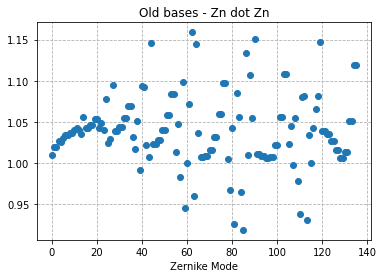

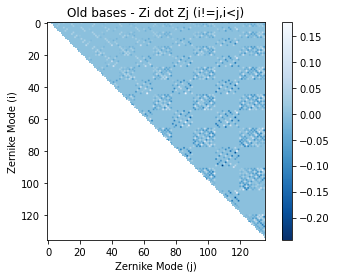

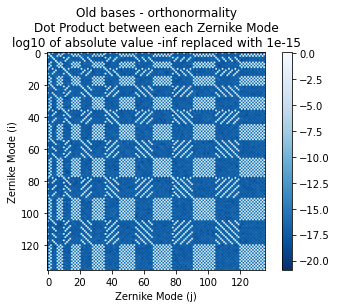

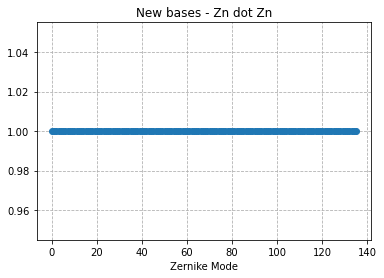

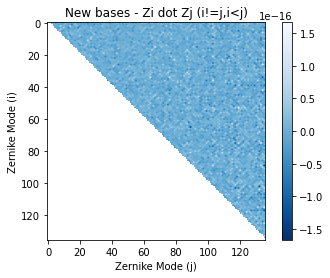

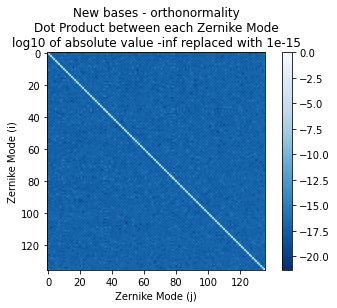

<Figure size 432x288 with 0 Axes>

In [10]:
## 7 ## Make orthonormalized zernike corrections ##

#based on sample_scrn_size not scrn_size

## Regular bases ## (use for old & my method)

#make flatten zernike modes
flat_modes=[]
modes=zernike.zernikeArray(Nzernike,sample_scrn_size)
for i in np.arange(Nzernike):
    flat_modes.append(flat_pupil*modes[i].flatten())

# TESTS #
# Make orthonormal matrix
orthonormality=np.zeros((Nzernike,Nzernike))

area=np.pi*(sample_scrn_size/2.0)**2

# Normality
normality_check=np.zeros(Nzernike)
for i in np.arange(Nzernike):
    normality_check[i]=np.dot(flat_modes[i],flat_modes[i])/area
    orthonormality[i,i]=normality_check[i]

plt.plot(normality_check,ls='',marker='o')
plt.xlabel('Zernike Mode')
#plt.ylim((0,max(normality_check)))
plt.title('Old bases - Zn dot Zn')
plt.grid(True,which="both", linestyle='--')
plt.savefig('OldBasesNormality')
plt.show()
plt.clf()

# Orthogonality
orthogonality_check=np.empty((Nzernike,Nzernike))
orthogonality_check[:,:]=np.NaN
for i in np.arange(Nzernike):
    for j in np.arange(Nzernike):
        if i!=j:
            if i<j:
                orthogonality_check[i,j]=np.dot(flat_modes[i],flat_modes[j])/area
                orthonormality[i,j]=orthogonality_check[i,j]
                orthonormality[j,i]=orthogonality_check[i,j]

orthonormality_copy=orthonormality
orthonormality_copy[np.where(orthonormality==0)]=1e-15
                
plt.imshow(orthogonality_check,cmap=reversed_color_map)
plt.xlabel('Zernike Mode (j)')
plt.ylabel('Zernike Mode (i)')
plt.title('Old bases - Zi dot Zj (i!=j,i<j)')
plt.colorbar()
plt.savefig('OldBasesOrthogonality')
plt.show()
plt.clf()

plt.imshow(np.log(np.abs(orthonormality_copy))/np.log(10),cmap=reversed_color_map)
plt.xlabel('Zernike Mode (j)')
plt.ylabel('Zernike Mode (i)')
plt.title('Old bases - orthonormality\nDot Product between each Zernike Mode\nlog10 of absolute value -inf replaced with 1e-15')
plt.colorbar()
plt.savefig('OldBassesOrthonormality')
plt.show()
plt.clf()


## Gram-Schmidt Orthogonormalized Method ##

#make flatten zernike modes
#flat_modes=[]
#modes=zernike.zernikeArray(Nzernike,sample_scrn_size)
#for i in np.arange(Nzernike):
#    flat_modes.append(flat_pupil*modes[i].flatten())

#Want orthonormalized bases -- z'_i which is orthonormalized z_i
#Z_i=original zernike         -->  orthonormalized but impossible to make
#z_i=replicated zernike       -->  close enough to zernike but not orthonormalized
#z'_i=orthonormalized z_i     -->  close enough to zernike and orthonormalized

#create a function which take in set of not orthonormal bases  -->  z_i
#                  then  return set of orthonormalized bases   -->  z'_i

#https://en.wikipedia.org/wiki/Gram%E2%80%93Schmidt_process

v=flat_modes #z_i
N=len(v)
u=[] #orthogonalized z'_i but need to be normalized
e=[] #orthogonalized and normalized z'_i
for i in np.arange(N):
    if i==0:
        u.append(v[0])
    else:
        u.append(v[i])
        for j in np.arange(i):
            u[i]=u[i]-(np.dot(u[j],v[i])/np.dot(u[j],u[j]))*u[j]
            
for i in np.arange(N):
    e.append(u[i]/np.sqrt(np.dot(u[i],u[i])))
    
## TEST ##
# Make orthonormal matrix
new_orthonormality=np.zeros((Nzernike,Nzernike))

# Normality
new_normality_check=np.zeros(Nzernike)
for i in np.arange(Nzernike):
    new_normality_check[i]=np.dot(e[i],e[i])
    new_orthonormality[i,i]=new_normality_check[i]

plt.plot(new_normality_check,ls='',marker='o')
plt.xlabel('Zernike Mode')
#plt.ylim((0,max(normality_check)))
plt.title('New bases - Zn dot Zn')
plt.grid(True,which="both", linestyle='--')
plt.savefig('NewBasesNormality')
plt.show()
plt.clf()

# Orthogonality
new_orthogonality_check=np.empty((Nzernike,Nzernike))
new_orthogonality_check[:,:]=np.NaN
for i in np.arange(Nzernike):
    for j in np.arange(Nzernike):
        if i!=j:
            if i<j:
                new_orthogonality_check[i,j]=np.dot(e[i],e[j])
                new_orthonormality[i,j]=new_orthogonality_check[i,j]
                new_orthonormality[j,i]=new_orthogonality_check[i,j]

new_orthonormality_copy=new_orthonormality
new_orthonormality_copy[np.where(new_orthonormality==0)]=1e-15
                
plt.imshow(new_orthogonality_check,cmap=reversed_color_map)
plt.xlabel('Zernike Mode (j)')
plt.ylabel('Zernike Mode (i)')
plt.title('New bases - Zi dot Zj (i!=j,i<j)')
plt.colorbar()
plt.savefig('NewBasesOrthogonality')
plt.show()
plt.clf()

plt.imshow(np.log(np.abs(new_orthonormality_copy))/np.log(10),cmap=reversed_color_map)
plt.xlabel('Zernike Mode (j)')
plt.ylabel('Zernike Mode (i)')
plt.title('New bases - orthonormality\nDot Product between each Zernike Mode\nlog10 of absolute value -inf replaced with 1e-15')
plt.colorbar()
plt.savefig('NewBasesOrthonormality')
plt.show()
plt.clf()



In [11]:
## 8 ## Generate 10,000 phase screens ##

#of sample_scrn_size which is the 'observe' range. the scrn_size is the 'generate' range
phase_screen=infinitephasescreen.PhaseScreenVonKarman(scrn_size,pixel_scale,r0,L0)
#coeffs=np.zeros((Nrandomscreens,Nzernike)) #coeffs[sample,mode]
new_coeffs=np.zeros((Nrandomscreens,Nzernike)) #new_coeffs[sample,mode]
#my_coeffs=[]
#phase_dot_modes=np.zeros(Nzernike)
#inverse_orthonormality=np.linalg.inv(orthonormality)

for i in np.arange(Nrandomscreens):
    phase_screen.make_initial_screen()
    phase=phase_screen.scrn[0:sample_scrn_size,0:sample_scrn_size]
    phase=phase.flatten()*flat_pupil
    
## 9 ## Fit zernike using orthonormalized method ##

# regular method --> cns=phase dot modes
#    for j in range(Nzernike):
#        coeffs[i,j]=np.dot(phase,flat_modes[j])/area
        
# gram-schmidt bases (new)
    for j in range(Nzernike):
        new_coeffs[i,j]=np.dot(phase,e[j])
    if i%100==0:
        print(i)

# my method ...
#    for j in np.arange(Nzernike):
#        phase_dot_modes[j]=np.dot(phases[i],flat_modes[j])/area
#    my_coeffs.append(np.matmul(inverse_orthonormality,phase_dot_modes))

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
5000
5100
5200
5300
5400
5500
5600
5700
5800
5900
6000
6100
6200
6300
6400
6500
6600
6700
6800
6900
7000
7100
7200
7300
7400
7500
7600
7700
7800
7900
8000
8100
8200
8300
8400
8500
8600
8700
8800
8900
9000
9100
9200
9300
9400
9500
9600
9700
9800
9900


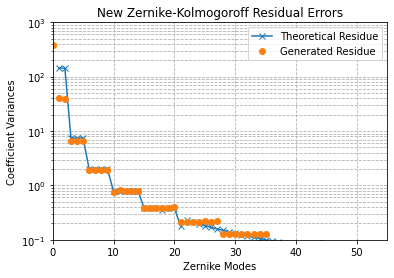

<Figure size 432x288 with 0 Axes>

In [12]:
## 10 ## Make residual error plot ##

#coeffs shape = (Nrandomscreens,Nzernike)
#variance_cns=np.zeros(Nzernike)
#my_variance_cns=np.zeros(Nzernike)
new_variance_cns=np.zeros(Nzernike)

for i in np.arange(Nzernike): # for each zernike mode
#    mean_cns[i]=np.mean(coeffs[:,i]) # through all samples
#    variance_cns[i]=np.var(coeffs[:,i])
#    my_variance_cns[i]=np.var(my_coeffs[:,i])
    new_variance_cns[i]=np.var(new_coeffs[:,i])

#old bases - regular method - plot
#
#temp=np.array([1.0299,0.582,0.134,0.111,0.0880,
#      0.0648,0.0587,0.0525,0.0463,0.0401,
#      0.0377,0.0352,0.0328,0.0304,0.0279,
#      0.0267,0.0255,0.0243,0.0232,0.0220,0.0208])
#
#res=[]
#for i in range(len(temp)-1):
#    res.append(temp[i]-temp[i+1])
#    
#if Nzernike>=20:
#    temp2=np.arange(22,Nzernike+1)
#    res.append(temp[-1]-0.2944*temp2[0]**(-np.sqrt(3)/2.))
#    for i in range(len(temp2)-2):
#        res.append(0.2944*((temp2[i+1])**(-np.sqrt(3)/2.)-(temp2[i+2])**(-np.sqrt(3)/2.)))
#    plt.plot(np.arange(Nzernike-2)+1,np.array(res)*(sample_scrn_size*pixel_scale/r0)**(5./3.),label='Theoretical Residue',marker='x')
#else:
#    plt.plot(np.arange(0,Nzernike)+1,np.array(res)[0:Nzernike]*(sample_scrn_size*pixel_scale/r0)**(5./3.),label='Theoretical Residue')
#
#plt.plot(variance_cns,marker='o',ls='',label='Generated Residue')
#plt.title('Old Zernike-Kolmogoroff Residual Errors')
#plt.xlabel('Zernike Modes')
#plt.ylabel('Coefficient Variances')
#plt.yscale('log')
#plt.grid(True,which="both", linestyle='--')
#plt.legend()
#plt.savefig('OldResidualErrors')
#plt.show()
#plt.clf()

#old bases - my method - plot

#temp=np.array([1.0299,0.582,0.134,0.111,0.0880,
#      0.0648,0.0587,0.0525,0.0463,0.0401,
#      0.0377,0.0352,0.0328,0.0304,0.0279,
#      0.0267,0.0255,0.0243,0.0232,0.0220,0.0208])
#
#res=[]
#for i in range(len(temp)-1):
#    res.append(temp[i]-temp[i+1])
#    
#if Nzernike>=20:
#    temp2=np.arange(22,Nzernike+1)
#    res.append(temp[-1]-0.2944*temp2[0]**(-np.sqrt(3)/2.))
#    for i in range(len(temp2)-2):
#        res.append(0.2944*((temp2[i+1])**(-np.sqrt(3)/2.)-(temp2[i+2])**(-np.sqrt(3)/2.)))
#    plt.plot(np.arange(Nzernike-2)+1,np.array(res)*(sample_scrn_size*pixel_scale/r0)**(5./3.),label='Theoretical Residue',marker='x')
#else:
#    plt.plot(np.arange(0,Nzernike)+1,np.array(res)[0:Nzernike]*(sample_scrn_size*pixel_scale/r0)**(5./3.),label='Theoretical Residue')
#
#plt.plot(my_variance_cns,marker='o',ls='',label='Generated Residue')
#plt.title('My Zernike-Kolmogoroff Residual Errors')
#plt.xlabel('Zernike Modes')
#plt.ylabel('Coefficient Variances')
#plt.yscale('log')
#plt.grid(True,which="both", linestyle='--')
#plt.legend()
#plt.savefig('MyResidualErrors')
#plt.show()
#plt.clf()

#new bases - plot

temp=np.array([1.0299,0.582,0.134,0.111,0.0880,
      0.0648,0.0587,0.0525,0.0463,0.0401,
      0.0377,0.0352,0.0328,0.0304,0.0279,
      0.0267,0.0255,0.0243,0.0232,0.0220,0.0208])

res=[]
for i in range(len(temp)-1):
    res.append(temp[i]-temp[i+1])
    
if Nzernike>=20:
    temp2=np.arange(22,Nzernike+1)
    res.append(temp[-1]-0.2944*temp2[0]**(-np.sqrt(3)/2.))
    for i in range(len(temp2)-2):
        res.append(0.2944*((temp2[i+1])**(-np.sqrt(3)/2.)-(temp2[i+2])**(-np.sqrt(3)/2.)))
    plt.plot(np.arange(Nzernike-2)+1,np.array(res)*(sample_scrn_size*pixel_scale/r0)**(5./3.),label='Theoretical Residue',marker='x')
else:
    plt.plot(np.arange(0,Nzernike)+1,np.array(res)[0:Nzernike]*(sample_scrn_size*pixel_scale/r0)**(5./3.),label='Theoretical Residue')

plt.plot(new_variance_cns/area,marker='o',ls='',label='Generated Residue')
plt.title('New Zernike-Kolmogoroff Residual Errors')
plt.xlabel('Zernike Modes')
plt.ylabel('Coefficient Variances')
plt.yscale('log')
plt.ylim(0.1,1000)
plt.xlim(0,55)
plt.grid(True,which="both", linestyle='--')
plt.legend()
plt.savefig('NewResidualErrors')
plt.show()
plt.clf()

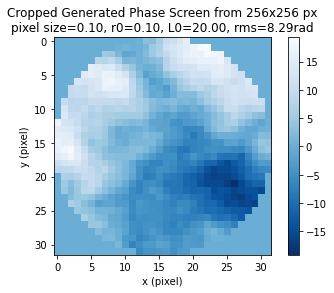

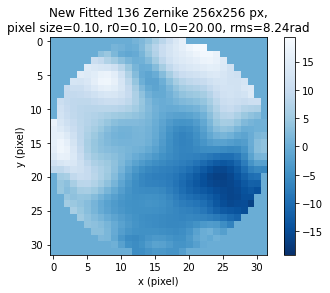

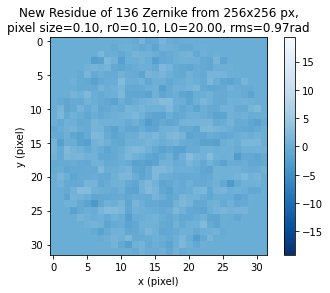

<Figure size 432x288 with 0 Axes>

In [13]:
## tests

## Regular method

#observe=phase.reshape((sample_scrn_size,sample_scrn_size))
#calculate=zernike.phaseFromZernikes(coeffs[-1],sample_scrn_size)*pupil
#residue=observe-calculate
#
#obs_rms=0.
#calc_rms=0.
#res_rms=0.
#
#obs_n=pupil.sum()
#calc_n=pupil.sum()
#res_n=pupil.sum()
#
#obs_mean=(pupil*observe).sum()/obs_n
#calc_mean=(pupil*calculate).sum()/calc_n
#res_mean=(pupil*residue).sum()/res_n
#
#for i in np.arange(sample_scrn_size):
#    for j in np.arange(sample_scrn_size):
#        if pupil[i,j]==1:
#            obs_rms=obs_rms+(observe[i,j]-obs_mean)**2
#            calc_rms=calc_rms+(calculate[i,j]-calc_mean)**2
#            res_rms=res_rms+(residue[i,j]-res_mean)**2
#            
#obs_rms=np.sqrt(obs_rms/(obs_n-1))
#calc_rms=np.sqrt(calc_rms/(calc_n-1))
#res_rms=np.sqrt(res_rms/(res_n-1))
#
#mapmax=observe.max()
#mapmin=observe.min()
#
#plt.imshow(observe,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
#plt.xlabel('x (pixel)')
#plt.ylabel('y (pixel)')
#plt.title('Cropped Generated Phase Screen from {:d}x{:d} px,\npixel size={:.2f}, r0={:.2f}, L0={:.2f}, rms={:.2f}rad'
#          .format(int(scrn_size),int(scrn_size),pixel_scale,r0,L0,obs_rms))
#plt.colorbar()
#plt.savefig('PhaseScreen')
#plt.show()
#plt.clf()
#
#plt.imshow(calculate,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
#plt.colorbar()
#plt.title('Old Fitted {:d} Zernike, from {:d}x{:d} px,\npixel size={:.2f}, r0={:.2f}, L0={:.2f}, rms={:.2f}rad'
#          .format(Nzernike,int(scrn_size),int(scrn_size),pixel_scale,r0,L0,calc_rms))
#plt.xlabel('x (pixel)')
#plt.ylabel('y (pixel)')
#plt.savefig('OldFittedZernike')
#plt.show()
#plt.clf()
#
#plt.imshow(residue,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
#plt.colorbar()
#plt.title('Old Residue of {:d} Zernike from {:d}x{:d} px,\npixel size={:.2f}, r0={:.2f}, L0={:.2f}, rms={:.2f}rad'
#          .format(Nzernike,int(scrn_size),int(scrn_size),pixel_scale,r0,L0,res_rms))
#plt.xlabel('x (pixel)')
#plt.ylabel('y (pixel)')
#plt.savefig('OldResidue')
#plt.show()
#plt.clf()



## My method
#
#observe=phases[test_scrn].reshape((sample_scrn_size,sample_scrn_size))
#calculate=zernike.phaseFromZernikes(my_coeffs[test_scrn],sample_scrn_size)*pupil
#residue=observe-calculate
#
#obs_rms=0.
#calc_rms=0.
#res_rms=0.
#
#obs_n=pupil.sum()
#calc_n=pupil.sum()
#res_n=pupil.sum()
#
#obs_mean=(pupil*observe).sum()/obs_n
#calc_mean=(pupil*calculate).sum()/calc_n
#res_mean=(pupil*residue).sum()/res_n
#
#for i in np.arange(sample_scrn_size):
#    for j in np.arange(sample_scrn_size):
#        if pupil[i,j]==1:
#            #obs_rms=obs_rms+(observe[i,j]-obs_mean)**2
#            calc_rms=calc_rms+(calculate[i,j]-calc_mean)**2
#            res_rms=res_rms+(residue[i,j]-res_mean)**2
#            
#obs_rms=np.sqrt(obs_rms/(obs_n-1))
#calc_rms=np.sqrt(calc_rms/(calc_n-1))
#res_rms=np.sqrt(res_rms/(res_n-1))
#
#mapmax=observe.max()
#mapmin=observe.min()
#
#plt.imshow(observe,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
#plt.xlabel('x (pixel)')
#plt.ylabel('y (pixel)')
#plt.title('Cropped Generated Phase Screen from {:d}x{:d} px\npixel size={:.2f}, r0={:.2f}, L0={:.2f}, rms={:.2f}rad'
#          .format(int(scrn_size),int(scrn_size),pixel_scale,r0,L0,obs_rms))
#plt.colorbar()
#plt.savefig('PhaseScreen')
#plt.show()
#plt.clf()
#
#plt.imshow(calculate,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
#plt.colorbar()
#plt.title('My Fitted {:d} Zernike from {:d}x{:d} px,\npixel size={:.2f}, r0={:.2f}, L0={:.2f}, rms={:.2f}rad'
#          .format(Nzernike,int(scrn_size),int(scrn_size),pixel_scale,r0,L0,calc_rms))
#plt.xlabel('x (pixel)')
#plt.ylabel('y (pixel)')
#plt.savefig('MyFittedZernike')
#plt.show()
#plt.clf()
#
#plt.imshow(residue,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
#plt.colorbar()
#plt.title('My Residue of {:d} Zernike from {:d}x{:d} px,\npixel size={:.2f}, r0={:.2f}, L0={:.2f}, rms={:.2f}rad'
#          .format(Nzernike,int(scrn_size),int(scrn_size),pixel_scale,r0,L0,res_rms))
#plt.xlabel('x (pixel)')
#plt.ylabel('y (pixel)')
#plt.savefig('MyResidue')
#plt.show()
#plt.clf()



## New method

observe=phase.reshape((sample_scrn_size,sample_scrn_size))
temp_calculate=np.zeros(sample_scrn_size**2)
for i in np.arange(Nzernike):
    temp_calculate=temp_calculate+new_coeffs[-1,i]*e[i]
    
calculate=temp_calculate.reshape((sample_scrn_size,sample_scrn_size))
residue=observe-calculate

obs_rms=0.
calc_rms=0.
res_rms=0.

obs_n=pupil.sum()
calc_n=pupil.sum()
res_n=pupil.sum()

obs_mean=(pupil*observe).sum()/obs_n
calc_mean=(pupil*calculate).sum()/calc_n
res_mean=(pupil*residue).sum()/res_n

for i in np.arange(sample_scrn_size):
    for j in np.arange(sample_scrn_size):
        if pupil[i,j]==1:
            obs_rms=obs_rms+(observe[i,j]-obs_mean)**2
            calc_rms=calc_rms+(calculate[i,j]-calc_mean)**2
            res_rms=res_rms+(residue[i,j]-res_mean)**2
            
obs_rms=np.sqrt(obs_rms/(obs_n-1))
calc_rms=np.sqrt(calc_rms/(calc_n-1))
res_rms=np.sqrt(res_rms/(res_n-1))

mapmax=observe.max()
mapmin=observe.min()

plt.imshow(observe,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.title('Cropped Generated Phase Screen from {:d}x{:d} px\npixel size={:.2f}, r0={:.2f}, L0={:.2f}, rms={:.2f}rad'
          .format(int(scrn_size),int(scrn_size),pixel_scale,r0,L0,obs_rms))
plt.colorbar()
plt.savefig('PhaseScreen')
plt.show()
plt.clf()

plt.imshow(calculate,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.colorbar()
plt.title('New Fitted {:d} Zernike {:d}x{:d} px,\npixel size={:.2f}, r0={:.2f}, L0={:.2f}, rms={:.2f}rad'
          .format(Nzernike,int(scrn_size),int(scrn_size),pixel_scale,r0,L0,calc_rms))
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.savefig('NewFittedZernike')
plt.show()
plt.clf()

plt.imshow(residue,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.colorbar()
plt.title('New Residue of {:d} Zernike from {:d}x{:d} px,\npixel size={:.2f}, r0={:.2f}, L0={:.2f}, rms={:.2f}rad'
          .format(Nzernike,int(scrn_size),int(scrn_size),pixel_scale,r0,L0,res_rms))
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.savefig('NewResidue')
plt.show()
plt.clf()

In [14]:
from astropy.io import fits
hdu = fits.PrimaryHDU()
hdu.data = new_coeffs
hdu.header['scrn_size']='{:d}'.format(scrn_size)
hdu.header['Nrandomscreens']='{:d}'.format(Nrandomscreens)
hdu.header['r0']='{:.2f}'.format(r0)
hdu.header['L0']='{:.2f}'.format(L0)
hdu.header['sample_scrn_size']='{:d}'.format(sample_scrn_size)
hdu.header['l0']='{:.2f}'.format(l0)
hdu.header['pixel_scale']='{:.2f}'.format(pixel_scale)
hdu.writeto('{:d}x{:2d}finalFlatPhaseScreens.fit'.format(Nrandomscreens,scrn_size))